# 05. Métodos de Ensemble: Random Forest e Gradient Boosting

**DCT1401 — Inteligência Artificial (UFRN, 2026.2)**  
**Aluna:** Mariana dos Santos Batista Medeiros (Matrícula: 20230083988)

**Atividade 02 — Avaliação Comparativa de Modelos**

Este notebook desenvolve e avalia os métodos Random Forest e Gradient Boosting para classificação de `Cardiovascular_Disease` e regressão de `Risk_Score`, conforme os requisitos da Seção 4 do enunciado.

A análise contempla o treinamento e a seleção de hiperparâmetros dos modelos, a comparação de desempenho, a influência do número de árvores sobre o erro e a importância das variáveis preditoras.

Também são discutidas as características de cada abordagem, especialmente a redução da variância pela Random Forest e a construção sequencial de modelos no Gradient Boosting.

São utilizadas as mesmas seis variáveis selecionadas na Atividade 01 e a divisão de 80% para treinamento e 20% para teste, com estratificação da classificação e `random_state=42`.

O ajuste dos hiperparâmetros utiliza validação cruzada de cinco folds, com pré-processamento incorporado aos `Pipelines` para evitar *data leakage*. As métricas principais de seleção são o F1-score na classificação e o RMSE na regressão.

Ao final, os modelos selecionados são salvos para as avaliações comparativas, de generalização e de eficiência computacional dos notebooks seguintes.

**Configuração do ambiente — Google Colab**

Esta etapa conecta o Google Colab ao Google Drive e configura os caminhos necessários para acessar o dataset original e os módulos Python do projeto.

A execução pressupõe que a pasta `projeto-cardiovascular-ia-02` esteja localizada em `Meu Drive`, conforme as instruções disponíveis no `README.md` da Atividade 02.

O código verifica a existência do dataset e prepara o ambiente para a execução das etapas seguintes.

In [ ]:
from google.colab import drive
from pathlib import Path
import os
import sys
import importlib

# Conectar ao Google Drive
drive.mount("/content/drive")

# Localizar o projeto
PROJETO = Path(
    "/content/drive/MyDrive/projeto-cardiovascular-ia-02"
)

assert (PROJETO / "data/raw/cardiovascular_disease_prediction.csv").is_file(), "Dataset original não encontrado!"
os.chdir(PROJETO / "notebooks")

if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))

# Importar a versão atualizada
import src.models as modelos
importlib.reload(modelos)

# Verificar as quatro funções
funcoes = [
    "treinar_random_forest_classificacao",
    "treinar_random_forest_regressao",
    "treinar_gradient_boosting_classificacao",
    "treinar_gradient_boosting_regressao"
]

for nome in funcoes:
    assert callable(getattr(modelos, nome))
    print(f"OK: {nome}")

print("\nMódulo models.py carregado com sucesso!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK: treinar_random_forest_classificacao
OK: treinar_random_forest_regressao
OK: treinar_gradient_boosting_classificacao
OK: treinar_gradient_boosting_regressao

Módulo models.py carregado com sucesso!


## 1. Preparação dos dados e protocolo experimental

Os experimentos utilizam as mesmas seis variáveis selecionadas na Atividade 01 e a mesma divisão de dados adotada nos Notebooks 03 e 04.

O conjunto é dividido em 80% para treinamento e 20% para teste, com `random_state=42` e estratificação pela variável de classificação. O pré-processamento será realizado dentro dos Pipelines, evitando vazamento de informações durante a validação cruzada.

O conjunto de teste permanecerá reservado para a avaliação final dos modelos.


In [ ]:
import src.pipeline_data as pipeline_data
importlib.reload(pipeline_data)

(
    X_train,
    X_test,
    y_train_c,
    y_test_c,
    y_train_r,
    y_test_r,
    feat_cols
) = pipeline_data.carregar_e_dividir_dados_sem_leakage(
    "../data/raw/cardiovascular_disease_prediction.csv"
)

print("Registros de treinamento:", len(X_train))
print("Registros de teste:", len(X_test))

print("\nVariáveis utilizadas:")
for coluna in feat_cols:
    print("-", coluna)

print("\nDistribuição da classe positiva:")
print(f"Treinamento: {y_train_c.mean():.2%}")
print(f"Teste: {y_test_c.mean():.2%}")

print("\nValores ausentes em Blood_Glucose:")
print("Treinamento:", X_train["Blood_Glucose"].isna().sum())
print("Teste:", X_test["Blood_Glucose"].isna().sum())

Registros de treinamento: 16000
Registros de teste: 4000

Variáveis utilizadas:
- Diabetes
- Hypertension
- Chest_Pain
- ECG_Result
- Blood_Glucose
- Blood_Pressure_Systolic

Distribuição da classe positiva:
Treinamento: 30.60%
Teste: 30.60%

Valores ausentes em Blood_Glucose:
Treinamento: 476
Teste: 124


In [ ]:
# Conferência da divisão e das variáveis utilizadas

assert len(X_train) == 16000
assert len(X_test) == 4000

assert len(feat_cols) == 6

assert X_train.index.intersection(X_test.index).empty

assert X_train.index.equals(y_train_c.index)
assert X_train.index.equals(y_train_r.index)

assert X_test.index.equals(y_test_c.index)
assert X_test.index.equals(y_test_r.index)

assert list(X_train.columns) == feat_cols
assert list(X_test.columns) == feat_cols

print("Verificação concluída!")
print("Divisão, índices e variáveis consistentes.")

Verificação concluída!
Divisão, índices e variáveis consistentes.


## 2. Random Forest para classificação

A Random Forest combina múltiplas árvores de decisão para realizar a classificação. O objetivo é reduzir a variância de uma árvore isolada e melhorar a capacidade de generalização.

A seleção de hiperparâmetros utiliza GridSearchCV com validação cruzada estratificada de cinco folds, adotando o F1-score como métrica principal. O pré-processamento permanece dentro do Pipeline.

Também são registrados o tempo total da busca, o pico de memória Python e as estimativas de energia e CO₂.

In [ ]:
import pandas as pd
import src.profiling as profiling

importlib.reload(profiling)

# Treinar e medir recursos computacionais na mesma execução
resultado_rf_c, medicao_rf_c = profiling.medir_treinamento(
    modelos.treinar_random_forest_classificacao,
    X_train,
    y_train_c,
    cv=5,
    random_state=42
)

# Pipeline completo com a Random Forest selecionada
rf_c = resultado_rf_c["modelo_ajustado"]

# Resultados da validação cruzada
print("RANDOM FOREST — CLASSIFICAÇÃO")

print("\nMelhores hiperparâmetros:")
for parametro, valor in resultado_rf_c["melhores_parametros"].items():
    print(f"{parametro}: {valor}")

f1_treino_cv = resultado_rf_c["score_treino_medio_cv"]
f1_validacao_cv = resultado_rf_c["melhor_score_cv"]

print("\nValidação cruzada — 5 folds:")
print(f"F1 médio de treinamento: {f1_treino_cv:.4f}")
print(f"F1 médio de validação: {f1_validacao_cv:.4f}")
print(f"Desvio padrão da validação: {resultado_rf_c['desvio_score_cv']:.4f}")
print(f"Gap treino - validação: {f1_treino_cv - f1_validacao_cv:.4f}")

# Eficiência computacional
energia_rf_c = profiling.estimar_energia_carbono(
    medicao_rf_c["tempo_treino_s"]
)

print("\nEficiência do treinamento:")
print(f"Tempo total: {medicao_rf_c['tempo_treino_s']:.4f} s")
print(f"Pico de memória Python: {medicao_rf_c['pico_memoria_treino_kb']:.2f} KB")
print(f"Energia estimada: {energia_rf_c['energia_kwh']:.8e} kWh")
print(f"CO2 estimado: {energia_rf_c['emissao_co2_g']:.8e} g")

RANDOM FOREST — CLASSIFICAÇÃO

Melhores hiperparâmetros:
modelo__max_depth: 6
modelo__max_features: 1.0
modelo__min_samples_leaf: 10
modelo__n_estimators: 50

Validação cruzada — 5 folds:
F1 médio de treinamento: 0.6312
F1 médio de validação: 0.6248
Desvio padrão da validação: 0.0061
Gap treino - validação: 0.0064

Eficiência do treinamento:
Tempo total: 53.9635 s
Pico de memória Python: 3137.38 KB
Energia estimada: 6.74543264e-04 kWh
CO2 estimado: 3.08940815e-02 g


### 2.1 Interpretação dos resultados

A Random Forest apresentou F1 médio de 0,6248 na validação cruzada, com desvio padrão de 0,0061. A diferença entre treinamento e validação foi de 0,0064, indicando estabilidade e ausência de evidência relevante de overfitting.

O resultado ficou ligeiramente abaixo do F1 de validação da árvore de decisão ajustada (0,6349). Portanto, a combinação de árvores não proporcionou melhoria nessa etapa. A comparação definitiva será realizada posteriormente, utilizando o conjunto de teste reservado.

**Observação metodológica — Random Forest e Bagging:** a busca selecionou `max_features=1.0`, configuração na qual todas as seis variáveis ficam disponíveis como candidatas em cada divisão. Assim, a subamostragem aleatória de variáveis por divisão — mecanismo que normalmente diferencia a Random Forest do Bagging de árvores — não atua nesta configuração. Permanece, porém, a reamostragem *bootstrap* dos registros, de modo que o comportamento se aproxima do Bagging. O estimador continua sendo `RandomForestClassifier`, conforme o enunciado; a escolha foi determinada pelo F1 da validação cruzada e não exige alterar o modelo após a avaliação final.

## 3. Random Forest para regressão

A Random Forest de regressão combina as previsões de múltiplas árvores para estimar o valor numérico de Risk_Score.

Os hiperparâmetros são selecionados por GridSearchCV com validação cruzada de cinco folds, utilizando RMSE como métrica principal. Valores menores de RMSE indicam melhores resultados.

O pré-processamento permanece dentro do Pipeline, e o conjunto de teste não é utilizado nesta etapa.

In [ ]:
# Treinar Random Forest de regressão e medir os recursos
resultado_rf_r, medicao_rf_r = profiling.medir_treinamento(
    modelos.treinar_random_forest_regressao,
    X_train,
    y_train_r,
    cv=5,
    random_state=42
)

# Pipeline completo da Random Forest selecionada
rf_r = resultado_rf_r["modelo_ajustado"]

print("RANDOM FOREST — REGRESSÃO")

print("\nMelhores hiperparâmetros:")
for parametro, valor in resultado_rf_r["melhores_parametros"].items():
    print(f"{parametro}: {valor}")

rmse_treino_cv = resultado_rf_r["score_treino_medio_cv"]
rmse_validacao_cv = resultado_rf_r["melhor_score_cv"]

print("\nValidação cruzada — 5 folds:")
print(f"RMSE médio de treinamento: {rmse_treino_cv:.4f}")
print(f"RMSE médio de validação: {rmse_validacao_cv:.4f}")
print(f"Desvio padrão da validação: {resultado_rf_r['desvio_score_cv']:.4f}")
print(f"Gap validação - treino: {rmse_validacao_cv - rmse_treino_cv:.4f}")

# Eficiência computacional
energia_rf_r = profiling.estimar_energia_carbono(
    medicao_rf_r["tempo_treino_s"]
)

print("\nEficiência do treinamento:")
print(f"Tempo total: {medicao_rf_r['tempo_treino_s']:.4f} s")
print(f"Pico de memória Python: {medicao_rf_r['pico_memoria_treino_kb']:.2f} KB")
print(f"Energia estimada: {energia_rf_r['energia_kwh']:.8e} kWh")
print(f"CO2 estimado: {energia_rf_r['emissao_co2_g']:.8e} g")

RANDOM FOREST — REGRESSÃO

Melhores hiperparâmetros:
modelo__max_depth: 6
modelo__max_features: 1.0
modelo__min_samples_leaf: 10
modelo__n_estimators: 100

Validação cruzada — 5 folds:
RMSE médio de treinamento: 2.9282
RMSE médio de validação: 2.9703
Desvio padrão da validação: 0.0408
Gap validação - treino: 0.0421

Eficiência do treinamento:
Tempo total: 42.7070 s
Pico de memória Python: 2951.49 KB
Energia estimada: 5.33837725e-04 kWh
CO2 estimado: 2.44497678e-02 g


### 3.1 Interpretação dos resultados

A Random Forest de regressão apresentou RMSE médio de 2,9703 na validação cruzada, com desvio padrão de 0,0408 e gap entre treinamento e validação de 0,0421, indicando estabilidade relativa.

O resultado foi ligeiramente melhor que o da Árvore de Decisão ajustada do Notebook 04, cujo RMSE médio de validação foi 2,9834. Entretanto, a diferença é pequena em relação à variabilidade entre os folds, não permitindo concluir superioridade estatística.

A avaliação definitiva será realizada posteriormente, utilizando o conjunto de teste reservado.

Assim como na classificação, a configuração selecionada usa `max_features=1.0`: todas as seis variáveis são candidatas em cada divisão, e a diversidade das árvores decorre principalmente do *bootstrap*. Portanto, nesta configuração, a Random Forest tem funcionamento próximo ao Bagging, embora permaneça implementada com `RandomForestRegressor`.

## 4. Gradient Boosting para classificação

O Gradient Boosting constrói árvores sequencialmente para melhorar progressivamente as previsões. São avaliados o número de árvores, a taxa de aprendizado, a profundidade das árvores-base e a fração de amostragem.

A seleção dos hiperparâmetros utiliza GridSearchCV com validação cruzada estratificada de cinco folds e F1-score como métrica principal.

O pré-processamento ocorre dentro do Pipeline, e o conjunto de teste permanece reservado para a avaliação final.

In [ ]:
# Treinar e medir o Gradient Boosting de classificação
resultado_gb_c, medicao_gb_c = profiling.medir_treinamento(
    modelos.treinar_gradient_boosting_classificacao,
    X_train,
    y_train_c,
    cv=5,
    random_state=42
)

# Pipeline completo selecionado
gb_c = resultado_gb_c["modelo_ajustado"]

print("GRADIENT BOOSTING — CLASSIFICAÇÃO")

print("\nMelhores hiperparâmetros:")
for parametro, valor in resultado_gb_c["melhores_parametros"].items():
    print(f"{parametro}: {valor}")

f1_treino_gb = resultado_gb_c["score_treino_medio_cv"]
f1_validacao_gb = resultado_gb_c["melhor_score_cv"]

print("\nValidação cruzada — 5 folds:")
print(f"F1 médio de treinamento: {f1_treino_gb:.4f}")
print(f"F1 médio de validação: {f1_validacao_gb:.4f}")
print(f"Desvio padrão da validação: {resultado_gb_c['desvio_score_cv']:.4f}")
print(f"Gap treino - validação: {f1_treino_gb - f1_validacao_gb:.4f}")

energia_gb_c = profiling.estimar_energia_carbono(
    medicao_gb_c["tempo_treino_s"]
)

print("\nEficiência do treinamento:")
print(f"Tempo total: {medicao_gb_c['tempo_treino_s']:.4f} s")
print(f"Pico de memória Python: {medicao_gb_c['pico_memoria_treino_kb']:.2f} KB")
print(f"Energia estimada: {energia_gb_c['energia_kwh']:.8e} kWh")
print(f"CO2 estimado: {energia_gb_c['emissao_co2_g']:.8e} g")

GRADIENT BOOSTING — CLASSIFICAÇÃO

Melhores hiperparâmetros:
modelo__learning_rate: 0.1
modelo__max_depth: 3
modelo__n_estimators: 50
modelo__subsample: 0.8

Validação cruzada — 5 folds:
F1 médio de treinamento: 0.6286
F1 médio de validação: 0.6239
Desvio padrão da validação: 0.0033
Gap treino - validação: 0.0048

Eficiência do treinamento:
Tempo total: 30.7905 s
Pico de memória Python: 2947.88 KB
Energia estimada: 3.84881576e-04 kWh
CO2 estimado: 1.76275762e-02 g


### 4.1 Interpretação dos resultados

O Gradient Boosting de classificação apresentou F1 médio de 0,6239 na validação cruzada, com desvio padrão de 0,0033 e gap entre treinamento e validação de 0,0048, indicando estabilidade e ausência de evidência relevante de overfitting.

Seu desempenho foi semelhante ao da Random Forest (F1 de 0,6248), mas inferior ao da Árvore de Decisão ajustada (F1 de 0,6349). O menor desvio padrão indica resultados mais consistentes entre os folds, embora isso não represente necessariamente maior capacidade preditiva.

A comparação definitiva será realizada posteriormente, utilizando o conjunto de teste reservado.

## 5. Gradient Boosting para regressão

O Gradient Boosting de regressão constrói árvores sequencialmente para reduzir os erros das previsões numéricas.

Os hiperparâmetros são selecionados por GridSearchCV com validação cruzada de cinco folds, utilizando RMSE como métrica principal. O pré-processamento permanece dentro do Pipeline, e o conjunto de teste fica reservado para a avaliação final.

In [ ]:
# Treinar e medir o Gradient Boosting de regressão
resultado_gb_r, medicao_gb_r = profiling.medir_treinamento(
    modelos.treinar_gradient_boosting_regressao,
    X_train,
    y_train_r,
    cv=5,
    random_state=42
)

# Pipeline completo selecionado
gb_r = resultado_gb_r["modelo_ajustado"]

print("GRADIENT BOOSTING — REGRESSÃO")

print("\nMelhores hiperparâmetros:")
for parametro, valor in resultado_gb_r["melhores_parametros"].items():
    print(f"{parametro}: {valor}")

rmse_treino_gb = resultado_gb_r["score_treino_medio_cv"]
rmse_validacao_gb = resultado_gb_r["melhor_score_cv"]

print("\nValidação cruzada — 5 folds:")
print(f"RMSE médio de treinamento: {rmse_treino_gb:.4f}")
print(f"RMSE médio de validação: {rmse_validacao_gb:.4f}")
print(f"Desvio padrão da validação: {resultado_gb_r['desvio_score_cv']:.4f}")
print(f"Gap validação - treino: {rmse_validacao_gb - rmse_treino_gb:.4f}")

# Eficiência computacional
energia_gb_r = profiling.estimar_energia_carbono(
    medicao_gb_r["tempo_treino_s"]
)

print("\nEficiência do treinamento:")
print(f"Tempo total: {medicao_gb_r['tempo_treino_s']:.4f} s")
print(f"Pico de memória Python: {medicao_gb_r['pico_memoria_treino_kb']:.2f} KB")
print(f"Energia estimada: {energia_gb_r['energia_kwh']:.8e} kWh")
print(f"CO2 estimado: {energia_gb_r['emissao_co2_g']:.8e} g")

GRADIENT BOOSTING — REGRESSÃO

Melhores hiperparâmetros:
modelo__learning_rate: 0.1
modelo__max_depth: 2
modelo__n_estimators: 100
modelo__subsample: 0.8

Validação cruzada — 5 folds:
RMSE médio de treinamento: 2.9479
RMSE médio de validação: 2.9627
Desvio padrão da validação: 0.0406
Gap validação - treino: 0.0147

Eficiência do treinamento:
Tempo total: 25.2906 s
Pico de memória Python: 2950.32 KB
Energia estimada: 3.16132108e-04 kWh
CO2 estimado: 1.44788506e-02 g


### 5.1 Interpretação dos resultados

O Gradient Boosting de regressão apresentou RMSE médio de 2,9627 na validação cruzada, com desvio padrão de 0,0406 e gap entre validação e treinamento de 0,0147. Esses resultados indicam estabilidade e ausência de evidência relevante de overfitting.

O modelo obteve RMSE ligeiramente inferior ao da Random Forest (2,9703) e ao da Árvore de Decisão ajustada (2,9834). Entretanto, as diferenças são pequenas em relação à variabilidade entre os folds, não permitindo concluir superioridade estatística.

A avaliação definitiva será realizada posteriormente, utilizando o conjunto de teste reservado.

## 6. Comparação preliminar dos ensembles

Os quatro modelos são comparados utilizando os resultados da validação cruzada de cinco folds. Para classificação, utiliza-se o F1-score (maior é melhor); para regressão, utiliza-se o RMSE (menor é melhor).

Esta comparação não utiliza o conjunto de teste.



In [ ]:
import pandas as pd

experimentos_cv = [
    ("Classificação", "Random Forest", resultado_rf_c),
    ("Classificação", "Gradient Boosting", resultado_gb_c),
    ("Regressão", "Random Forest", resultado_rf_r),
    ("Regressão", "Gradient Boosting", resultado_gb_r)
]

resumo_ensembles = []

for tarefa, nome, resultado in experimentos_cv:

    treino = resultado["score_treino_medio_cv"]
    validacao = resultado["melhor_score_cv"]

    # F1: maior é melhor. RMSE: menor é melhor.
    gap = (
        treino - validacao
        if tarefa == "Classificação"
        else validacao - treino
    )

    resumo_ensembles.append({
        "Tarefa": tarefa,
        "Modelo": nome,
        "Métrica": "F1" if tarefa == "Classificação" else "RMSE",
        "Média treino CV": treino,
        "Média validação CV": validacao,
        "Desvio padrão CV": resultado["desvio_score_cv"],
        "Gap": gap
    })

tabela_cv_ensembles = pd.DataFrame(resumo_ensembles)

display(tabela_cv_ensembles.round(4))

,Tarefa,Modelo,Métrica,Média treino CV,Média validação CV,Desvio padrão CV,Gap
0,Classificação,Random Forest,F1,0.6312,0.6248,0.0061,0.0064
1,Classificação,Gradient Boosting,F1,0.6286,0.6239,0.0033,0.0048
2,Regressão,Random Forest,RMSE,2.9282,2.9703,0.0408,0.0421
3,Regressão,Gradient Boosting,RMSE,2.9479,2.9627,0.0406,0.0147


## 7. Curva de erro em função do número de árvores

Para investigar o efeito da quantidade de árvores na Random Forest, são avaliadas configurações com 1, 10, 50, 100 e 200 árvores, mantendo fixos os demais hiperparâmetros selecionados anteriormente.

Na classificação, utiliza-se a taxa de erro (1 − acurácia); na regressão, o RMSE. Os resultados são calculados por validação cruzada de cinco folds, exclusivamente no conjunto de treinamento.

As curvas permitem analisar o comportamento do erro, a diferença entre treinamento e validação e a relação com o compromisso entre viés e variância. Esta etapa tem finalidade diagnóstica e não altera automaticamente os modelos já selecionados.

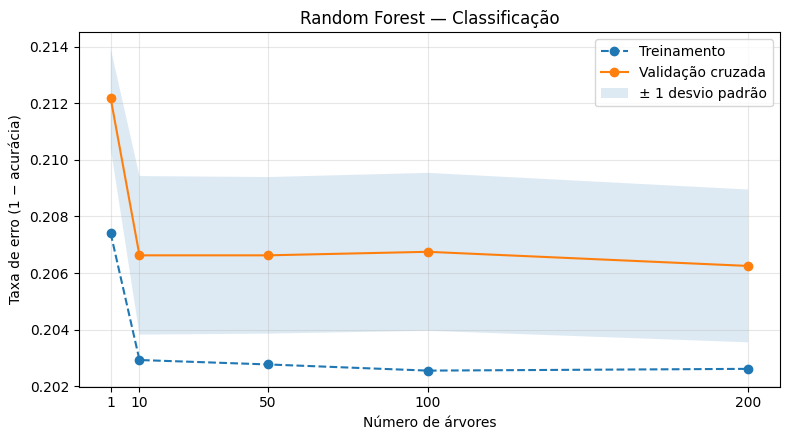


Resultados — classificacao:


,n_arvores,erro_treino_medio,erro_validacao_medio,desvio_validacao
0,1,0.2074,0.2122,0.0018
1,10,0.2029,0.2066,0.0028
2,50,0.2028,0.2066,0.0028
3,100,0.2025,0.2068,0.0028
4,200,0.2026,0.2062,0.0027


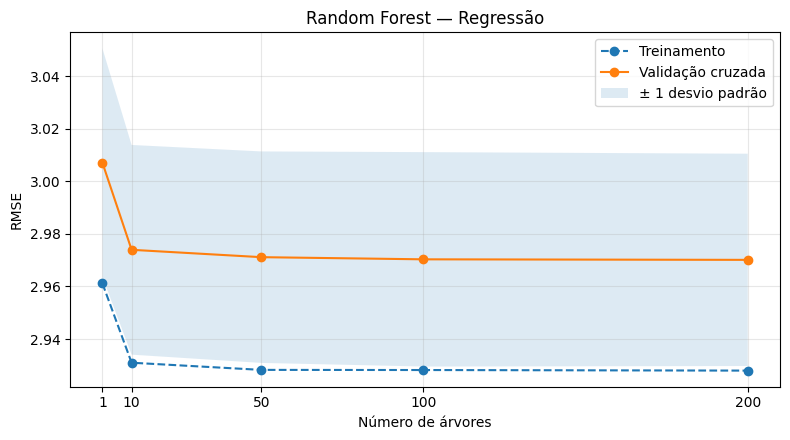


Resultados — regressao:


,n_arvores,erro_treino_medio,erro_validacao_medio,desvio_validacao
0,1,2.9612,3.0071,0.0435
1,10,2.9310,2.9740,0.0399
2,50,2.9283,2.9712,0.0403
3,100,2.9282,2.9703,0.0408
4,200,2.9280,2.9701,0.0404


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import (
    validation_curve, StratifiedKFold, KFold
)

pasta_figuras = PROJETO / "reports" / "figures"
pasta_tabelas = PROJETO / "reports" / "tables"

pasta_figuras.mkdir(parents=True, exist_ok=True)
pasta_tabelas.mkdir(parents=True, exist_ok=True)

quantidades_arvores = [1, 10, 50, 100, 200]


def gerar_curva_random_forest(
    pipeline, X, y, cv, scoring, tarefa
):
    # Reajusta o Pipeline dentro de cada fold.
    # Nenhum dado de teste é utilizado.
    scores_treino, scores_validacao = validation_curve(
        estimator=pipeline,
        X=X,
        y=y,
        param_name="modelo__n_estimators",
        param_range=quantidades_arvores,
        cv=cv,
        scoring=scoring,
        n_jobs=2
    )

    if tarefa == "classificacao":
        erros_treino = 1 - scores_treino
        erros_validacao = 1 - scores_validacao
        titulo = "Random Forest — Classificação"
        eixo_y = "Taxa de erro (1 − acurácia)"
    else:
        erros_treino = -scores_treino
        erros_validacao = -scores_validacao
        titulo = "Random Forest — Regressão"
        eixo_y = "RMSE"

    tabela = pd.DataFrame({
        "n_arvores": quantidades_arvores,
        "erro_treino_medio": erros_treino.mean(axis=1),
        "erro_validacao_medio": erros_validacao.mean(axis=1),
        "desvio_validacao": erros_validacao.std(axis=1)
    })

    fig, ax = plt.subplots(figsize=(8, 4.5))

    ax.plot(
        tabela["n_arvores"],
        tabela["erro_treino_medio"],
        marker="o",
        linestyle="--",
        label="Treinamento"
    )

    ax.plot(
        tabela["n_arvores"],
        tabela["erro_validacao_medio"],
        marker="o",
        label="Validação cruzada"
    )

    ax.fill_between(
        tabela["n_arvores"],
        tabela["erro_validacao_medio"] -
        tabela["desvio_validacao"],
        tabela["erro_validacao_medio"] +
        tabela["desvio_validacao"],
        alpha=0.15,
        label="± 1 desvio padrão"
    )

    ax.set_xticks(quantidades_arvores)
    ax.set_xlabel("Número de árvores")
    ax.set_ylabel(eixo_y)
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    ax.legend()

    fig.tight_layout()

    fig.savefig(
        pasta_figuras / f"rf_curva_erro_{tarefa}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    tabela.to_csv(
        pasta_tabelas / f"rf_curva_erro_{tarefa}.csv",
        index=False
    )

    print(f"\nResultados — {tarefa}:")
    display(tabela.round(4))

    return tabela


# Random Forest — Classificação
curva_rf_c = gerar_curva_random_forest(
    pipeline=rf_c,
    X=X_train,
    y=y_train_c,
    cv=StratifiedKFold(
        n_splits=5, shuffle=True, random_state=42
    ),
    scoring="accuracy",
    tarefa="classificacao"
)

# Random Forest — Regressão
curva_rf_r = gerar_curva_random_forest(
    pipeline=rf_r,
    X=X_train,
    y=y_train_r,
    cv=KFold(
        n_splits=5, shuffle=True, random_state=42
    ),
    scoring="neg_root_mean_squared_error",
    tarefa="regressao"
)

### 7.1 Interpretação das curvas e relação com viés e variância

Na classificação, o erro médio de validação caiu de **21,22%**, com uma árvore, para **20,66%**, com dez árvores; entre 10 e 200 árvores, permaneceu próximo desse nível (20,62% com 200 árvores). Na regressão, o RMSE de validação diminuiu de **3,0071** para **2,9740** entre uma e dez árvores, chegando a **2,9701** com 200 árvores.

O Bagging, utilizado pela Random Forest, busca principalmente **reduzir a variância** ao combinar árvores treinadas com amostras bootstrap. O ganho mais visível nas primeiras árvores, seguido de estabilização, é compatível com a redução da variabilidade da previsão e com o fato de que as previsões das árvores não são completamente independentes. As árvores-base também têm sua complexidade limitada por `max_depth=6` e `min_samples_leaf=10`, controles que tendem a reduzir a variância de cada árvore, mas podem limitar sua capacidade de representar relações mais complexas (**viés**).

**A estabilização do erro não representa uma medição direta do viés.** O patamar observado reflete o desempenho da configuração avaliada com as seis variáveis, podendo incluir viés do modelo, ruído dos dados e informação preditiva não disponível. Adicionar mais árvores não necessariamente corrige essas limitações.

As diferenças relativamente pequenas entre erros de treinamento e validação não indicam *overfitting* acentuado na faixa examinada, mas não demonstram, por si sós, ausência de *underfitting*.

As curvas são diagnósticas e não redefinem a seleção anterior: mantêm-se **50 árvores na classificação** (escolhidas por F1) e **100 na regressão** (escolhidas por RMSE). A curva de classificação utiliza `1 − acurácia`, portanto sua ordenação não precisa coincidir com a seleção por F1.

## 8. Importância das variáveis e comparação com o Sistema Especialista

A importância das seis variáveis é analisada nos modelos Random Forest e Gradient Boosting, tanto para classificação quanto para regressão.

Utiliza-se `feature_importances_`, que representa a contribuição relativa das variáveis para a redução de impureza nos modelos baseados em árvores.

Na classificação, os resultados serão comparados com a frequência de utilização das variáveis nas 11 regras do Sistema Especialista. Essa comparação tem caráter interpretativo, pois a frequência em regras e a importância estatística medem aspectos diferentes.

A importância não deve ser interpretada como causalidade ou relevância clínica comprovada.

**Limitação metodológica:** a importância por redução de impureza pode favorecer variáveis contínuas ou com muitos pontos de corte e distribuir importância entre variáveis correlacionadas. Por isso, os valores devem ser interpretados como importâncias internas do modelo, não como um ranking causal ou clínico definitivo.

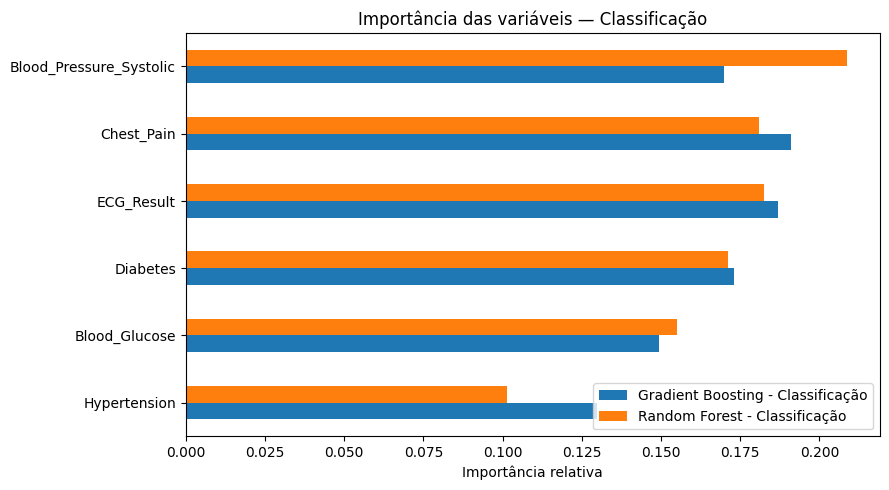

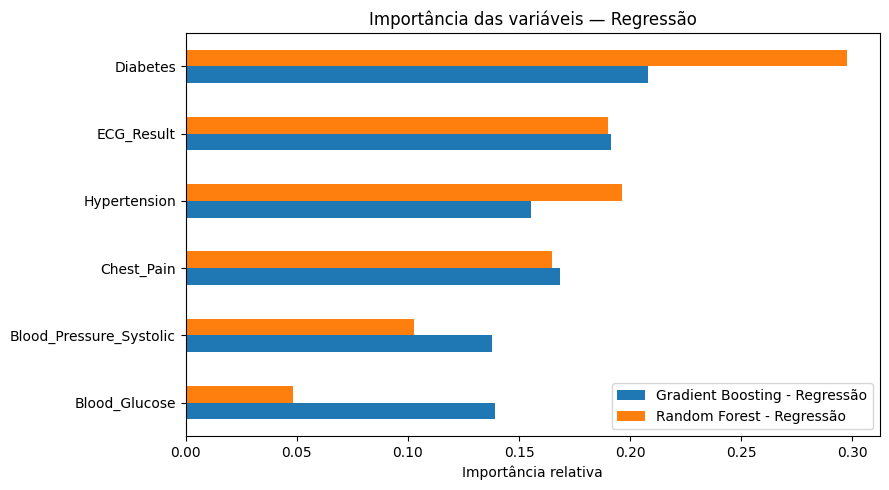


IMPORTÂNCIA DAS VARIÁVEIS


Modelo,Gradient Boosting - Classificação,Gradient Boosting - Regressão,Random Forest - Classificação,Random Forest - Regressão
Variável,,,,
Blood_Glucose,0.1493,0.1393,0.1552,0.0484
Blood_Pressure_Systolic,0.1700,0.1379,0.2087,0.1028
Chest_Pain,0.1909,0.1685,0.1811,0.1649
Diabetes,0.1730,0.2078,0.1711,0.2975
ECG_Result,0.1869,0.1912,0.1825,0.1901
Hypertension,0.1299,0.1552,0.1014,0.1962


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

modelos_importancia = {
    "Random Forest - Classificação": rf_c,
    "Gradient Boosting - Classificação": gb_c,
    "Random Forest - Regressão": rf_r,
    "Gradient Boosting - Regressão": gb_r
}

tabelas_importancia = []

for nome, pipeline in modelos_importancia.items():

    nomes_variaveis = pipeline[
        "preprocessamento"
    ].get_feature_names_out()

    importancias = pipeline[
        "modelo"
    ].feature_importances_

    assert len(nomes_variaveis) == len(importancias) == 6

    tabela = pd.DataFrame({
        "Modelo": nome,
        "Variável": nomes_variaveis,
        "Importância": importancias
    })

    tabelas_importancia.append(tabela)

importancia_ensembles = pd.concat(
    tabelas_importancia,
    ignore_index=True
)

# Salvar resultados
importancia_ensembles.to_csv(
    pasta_tabelas / "ensembles_importancia_variaveis.csv",
    index=False
)

# Gerar um gráfico para cada tarefa
for tarefa in ["Classificação", "Regressão"]:

    dados = importancia_ensembles[
        importancia_ensembles["Modelo"].str.endswith(tarefa)
    ]

    tabela_grafico = dados.pivot(
        index="Variável",
        columns="Modelo",
        values="Importância"
    )

    tabela_grafico = tabela_grafico.loc[
        tabela_grafico.mean(axis=1).sort_values().index
    ]

    ax = tabela_grafico.plot(
        kind="barh",
        figsize=(9, 5)
    )

    ax.set_title(f"Importância das variáveis — {tarefa}")
    ax.set_xlabel("Importância relativa")
    ax.set_ylabel("")
    ax.legend(loc="best")
    plt.tight_layout()

    plt.savefig(
        pasta_figuras /
        f"ensembles_importancia_{tarefa.lower()}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("\nIMPORTÂNCIA DAS VARIÁVEIS")

display(
    importancia_ensembles.pivot(
        index="Variável",
        columns="Modelo",
        values="Importância"
    ).round(4)
)

In [ ]:
import re

caminho_regras = (
    PROJETO / "rules" / "regras_classificacao.txt"
)

linhas = caminho_regras.read_text(
    encoding="utf-8"
).splitlines()

# Considerar somente linhas que definem regras
regras = [
    linha for linha in linhas
    if re.match(r"^RC\d+\s*\|", linha.strip())
]

assert len(regras) == 11, (
    f"Esperadas 11 regras, encontradas {len(regras)}."
)

frequencias = []

for variavel in feat_cols:

    quantidade = sum(
        bool(
            re.search(
                rf"\b{re.escape(variavel)}\b",
                linha.split("ENTÃO")[0]
            )
        )
        for linha in regras
    )

    frequencias.append({
        "Variável": variavel,
        "Número de regras": quantidade,
        "Percentual de regras": quantidade / len(regras)
    })

tabela_regras = pd.DataFrame(frequencias)

tabela_regras.to_csv(
    pasta_tabelas /
    "sistema_especialista_frequencia_variaveis.csv",
    index=False
)

print("FREQUÊNCIA DAS VARIÁVEIS NAS 11 REGRAS")
display(
    tabela_regras.sort_values(
        "Número de regras",
        ascending=False
    ).reset_index(drop=True)
)

FREQUÊNCIA DAS VARIÁVEIS NAS 11 REGRAS


,Variável,Número de regras,Percentual de regras
0,Diabetes,6,0.545455
1,Hypertension,6,0.545455
2,Chest_Pain,6,0.545455
3,ECG_Result,5,0.454545
4,Blood_Glucose,2,0.181818
5,Blood_Pressure_Systolic,2,0.181818


### 8.1 Interpretação da importância das variáveis

Nos modelos de classificação, a Random Forest atribuiu maior importância à pressão arterial sistólica (0,2087), enquanto o Gradient Boosting destacou a dor no peito (0,1909). Na regressão, ambos atribuíram maior importância à variável Diabetes, com valores de 0,2975 e 0,2078, respectivamente.

No Sistema Especialista, Diabetes, Hypertension e Chest_Pain aparecem em seis das onze regras cada, enquanto ECG_Result aparece em cinco. Blood_Glucose e Blood_Pressure_Systolic aparecem em duas regras cada.

A comparação revela semelhanças e diferenças entre as abordagens. A pressão arterial sistólica, por exemplo, aparece em apenas duas regras, mas possui a maior importância na Random Forest de classificação. Por outro lado, a hipertensão aparece em seis regras e apresenta a menor importância nesse mesmo modelo.

Essas diferenças não indicam necessariamente inconsistência: a frequência nas regras representa decisões de elaboração do Sistema Especialista, enquanto a importância nos ensembles é calculada a partir das reduções de impureza aprendidas nos dados.

Como o Sistema Especialista foi desenvolvido apenas para classificação, a comparação direta com suas regras considera os modelos classificadores. Os resultados de regressão são apresentados como análise complementar. As importâncias não representam relações causais nem relevância clínica comprovada.

Deve-se considerar ainda o viés da importância por redução de impureza em favor de atributos contínuos ou com muitas possibilidades de corte. Esse efeito pode contribuir para o destaque de `Blood_Pressure_Systolic` na Random Forest de classificação, sem demonstrar, isoladamente, que ela seja a variável clinicamente mais relevante. Uma análise por permutação seria uma verificação complementar possível, mas não foi necessária para a comparação solicitada.

## 9. Avaliação final dos ensembles

Os modelos tiveram seus hiperparâmetros definidos por validação cruzada, utilizando exclusivamente os dados de treinamento.

A avaliação final utiliza o conjunto de teste reservado, sem novos ajustes de hiperparâmetros. São calculadas as métricas obrigatórias e os gaps de generalização, permitindo identificar possíveis diferenças entre o desempenho de treinamento e o desempenho em dados não utilizados no ajuste.

### 9.1 Classificação

In [ ]:
import src.metrics as metricas

importlib.reload(metricas)

modelos_classificacao = {
    "Random Forest": rf_c,
    "Gradient Boosting": gb_c
}

resultados_classificacao = []
matrizes_ensembles = {}

for nome, pipeline in modelos_classificacao.items():

    for conjunto, X, y in [
        ("Treinamento", X_train, y_train_c),
        ("Teste", X_test, y_test_c)
    ]:
        previsoes = pipeline.predict(X)
        probabilidades = pipeline.predict_proba(X)[:, 1]

        resultado = metricas.calcular_metricas_classificacao(
            y, previsoes, probabilidades
        )

        if conjunto == "Teste":
            matrizes_ensembles[nome] = resultado["Confusion_Matrix"]

        resultados_classificacao.append({
            "Modelo": nome,
            "Conjunto": conjunto,
            **{
                chave: valor
                for chave, valor in resultado.items()
                if chave != "Confusion_Matrix"
            }
        })

tabela_metricas_ensembles_c = pd.DataFrame(
    resultados_classificacao
)

tabela_metricas_ensembles_c.to_csv(
    pasta_tabelas / "ensembles_metricas_classificacao.csv",
    index=False
)

print("MÉTRICAS DE CLASSIFICAÇÃO")
display(tabela_metricas_ensembles_c.round(4))

print("\nGAP DE GENERALIZAÇÃO — F1")

for nome in modelos_classificacao:
    dados = tabela_metricas_ensembles_c[
        tabela_metricas_ensembles_c["Modelo"] == nome
    ]

    f1_treino = dados.loc[
        dados["Conjunto"] == "Treinamento", "F1-score"
    ].iloc[0]

    f1_teste = dados.loc[
        dados["Conjunto"] == "Teste", "F1-score"
    ].iloc[0]

    print(
        f"{nome}: {f1_treino - f1_teste:.4f}"
    )

MÉTRICAS DE CLASSIFICAÇÃO


,Modelo,Conjunto,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Average_Precision
0,Random Forest,Treinamento,0.7976,0.7129,0.5670,0.6316,0.8285,0.7193,0.7186
1,Random Forest,Teste,0.7845,0.6874,0.5425,0.6064,0.8006,0.6925,0.6921
2,Gradient Boosting,Treinamento,0.7950,0.7054,0.5668,0.6285,0.8248,0.7075,0.7060
3,Gradient Boosting,Teste,0.7865,0.6884,0.5523,0.6129,0.8009,0.6947,0.6935



GAP DE GENERALIZAÇÃO — F1
Random Forest: 0.0252
Gradient Boosting: 0.0157


### 9.2 Interpretação dos resultados de classificação

No conjunto de teste, o Gradient Boosting apresentou acurácia de **0,7865**, F1-score de **0,6129** e ROC-AUC de **0,8009**, valores ligeiramente superiores aos da Random Forest (**0,7845**, **0,6064** e **0,8006**, respectivamente). Os gaps de F1 entre treinamento e teste foram de **0,0157** e **0,0252**, nessa ordem, sem evidência de *overfitting* acentuado.

Apesar da acurácia próxima de 79%, os valores de recall (**0,5523** e **0,5425**) mostram que ambos deixaram de identificar uma parcela importante da classe positiva. No entanto, os ensembles alcançaram **Average Precision de 0,6935 (Gradient Boosting) e 0,6921 (Random Forest)**, superiores aos valores observados no Sistema Especialista (**0,6213**) e na Árvore de Decisão ajustada (**0,6121**). A Average Precision resume a relação precisão–recall ao variar o limiar e revela melhor desempenho de ordenação dos registros positivos pelos ensembles, mesmo com F1 inferior no limiar de classificação utilizado.

O F1 foi calculado com o **limiar padrão de 0,5**, enquanto ROC-AUC e Average Precision avaliam as pontuações ao longo de diferentes limiares. A diferença entre os resultados **pode estar associada ao limiar escolhido**, mas não é possível atribuí-la exclusivamente a ele ou à concentração das probabilidades sem análise específica. O limiar não será ajustado com base no teste. As curvas ROC e Precision–Recall comparativas serão apresentadas no Notebook 06.

Assim, a escolha do melhor classificador depende da métrica e do custo dos falsos negativos e falsos positivos; uma acurácia maior não significa, necessariamente, maior sensibilidade.

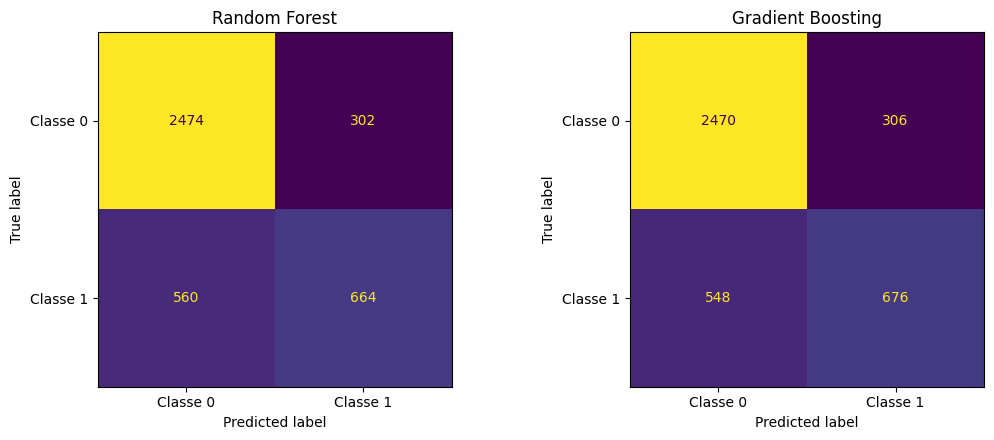


Random Forest
Verdadeiros negativos: 2474
Falsos positivos: 302
Falsos negativos: 560
Verdadeiros positivos: 664

Gradient Boosting
Verdadeiros negativos: 2470
Falsos positivos: 306
Falsos negativos: 548
Verdadeiros positivos: 676


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (nome, matriz) in zip(
    axes, matrizes_ensembles.items()
):
    visualizacao = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Classe 0", "Classe 1"]
    )

    visualizacao.plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    ax.set_title(nome)

plt.tight_layout()

plt.savefig(
    pasta_figuras / "cm_ensembles_classificacao.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

for nome, matriz in matrizes_ensembles.items():
    print(f"\n{nome}")
    print(f"Verdadeiros negativos: {matriz[0, 0]}")
    print(f"Falsos positivos: {matriz[0, 1]}")
    print(f"Falsos negativos: {matriz[1, 0]}")
    print(f"Verdadeiros positivos: {matriz[1, 1]}")

### 9.3 Regressão

A avaliação final de regressão utiliza as métricas MAE, MSE, RMSE, MAPE, R² e MedAE.

São calculados os resultados de treinamento e teste para verificar a capacidade de generalização dos modelos. Os hiperparâmetros permanecem fixos, conforme a seleção realizada anteriormente por validação cruzada.

In [ ]:
# Avaliação final da regressão

modelos_regressao = {
    "Random Forest": rf_r,
    "Gradient Boosting": gb_r
}

resultados_regressao = []

for nome, pipeline in modelos_regressao.items():

    for conjunto, X, y in [
        ("Treinamento", X_train, y_train_r),
        ("Teste", X_test, y_test_r)
    ]:
        previsoes = pipeline.predict(X)

        resultado = metricas.calcular_metricas_regressao(
            y, previsoes
        )

        resultados_regressao.append({
            "Modelo": nome,
            "Conjunto": conjunto,
            **resultado
        })

tabela_metricas_ensembles_r = pd.DataFrame(
    resultados_regressao
)

tabela_metricas_ensembles_r.to_csv(
    pasta_tabelas / "ensembles_metricas_regressao.csv",
    index=False
)

print("MÉTRICAS DE REGRESSÃO")

colunas_numericas = [
    "MAE", "MSE", "RMSE", "MAPE", "R2", "MedAE"
]

display(
    tabela_metricas_ensembles_r.style.format({
        coluna: (
            lambda valor:
            f"{valor:.3e}" if abs(valor) >= 1e6
            else f"{valor:.4f}"
        )
        for coluna in colunas_numericas
    })
)

print("\nGAP DE GENERALIZAÇÃO — RMSE")

for nome in modelos_regressao:

    dados = tabela_metricas_ensembles_r[
        tabela_metricas_ensembles_r["Modelo"] == nome
    ]

    rmse_treino = dados.loc[
        dados["Conjunto"] == "Treinamento",
        "RMSE"
    ].iloc[0]

    rmse_teste = dados.loc[
        dados["Conjunto"] == "Teste",
        "RMSE"
    ].iloc[0]

    print(f"{nome}: {rmse_teste - rmse_treino:.4f}")

MÉTRICAS DE REGRESSÃO


,Modelo,Conjunto,MAE,MSE,RMSE,MAPE,R2,MedAE
0,Random Forest,Treinamento,2.3521,8.6013,2.9328,1.701e+12,0.5110,2.0241
1,Random Forest,Teste,2.3704,8.7194,2.9529,0.5937,0.4819,2.0096
2,Gradient Boosting,Treinamento,2.3676,8.7037,2.9502,1.706e+12,0.5051,2.0378
3,Gradient Boosting,Teste,2.3701,8.7176,2.9526,0.5983,0.4820,2.0147



GAP DE GENERALIZAÇÃO — RMSE
Random Forest: 0.0201
Gradient Boosting: 0.0024


### 9.4 Interpretação da avaliação final

Na classificação, o Gradient Boosting apresentou desempenho ligeiramente superior ao da Random Forest no conjunto de teste, com F1-score de 0,6129 contra 0,6064. Entretanto, os valores de recall de 0,5523 e 0,5425 revelam que ambos deixaram de identificar uma parcela considerável dos registros positivos.

As matrizes de confusão mostram 548 falsos negativos para o Gradient Boosting e 560 para a Random Forest. Os gaps de F1 entre treinamento e teste foram de 0,0157 e 0,0252, respectivamente, sem evidências de overfitting acentuado.

Na regressão, os modelos apresentaram resultados muito próximos. O Gradient Boosting obteve RMSE de 2,9526 e R² de 0,4820, enquanto a Random Forest alcançou RMSE de 2,9529 e R² de 0,4819. Ambos superaram ligeiramente a Árvore de Decisão ajustada no conjunto de teste.

Na classificação, apesar dos F1-scores inferiores aos da Árvore de Decisão e do Sistema Especialista, os ensembles obtiveram Average Precision próxima de 0,69, superior à desses modelos (aproximadamente 0,61–0,62), indicando melhor capacidade de ordenar registros positivos. Essa comparação considera diferentes limiares e não demonstra que o limiar padrão de 0,5 seja a única causa das diferenças em F1.

Os gaps de RMSE foram de 0,0024 para o Gradient Boosting e 0,0201 para a Random Forest, indicando diferenças pequenas entre treinamento e teste.

Os valores extremamente elevados de MAPE no treinamento decorrem da presença de um valor exatamente igual a zero e de valores próximos de zero em Risk_Score no treinamento. Além disso, a presença de valores negativos limita sua interpretação percentual. Por esse motivo, a análise de regressão prioriza RMSE, MAE e R², mantendo o MAPE para atender aos requisitos da atividade.

## 10. Complexidade e persistência dos ensembles

A complexidade dos modelos é caracterizada pelo número de árvores, total de nós, total de folhas, profundidade máxima observada e tamanho serializado em disco.

Os quatro Pipelines completos são salvos para permitir sua reutilização nas análises comparativas, de generalização e eficiência computacional.

Os tempos e as estimativas de energia correspondem às buscas de hiperparâmetros já executadas, sem repetição do treinamento.

In [ ]:
import joblib
import numpy as np
import pandas as pd

pasta_modelos = PROJETO / "models"
pasta_modelos.mkdir(parents=True, exist_ok=True)

configuracoes = [
    ("Random Forest", "Classificação", rf_c,
     medicao_rf_c, "random_forest_clf.joblib"),

    ("Random Forest", "Regressão", rf_r,
     medicao_rf_r, "random_forest_reg.joblib"),

    ("Gradient Boosting", "Classificação", gb_c,
     medicao_gb_c, "gradient_boosting_clf.joblib"),

    ("Gradient Boosting", "Regressão", gb_r,
     medicao_gb_r, "gradient_boosting_reg.joblib")
]

registros_complexidade = []

for nome, tarefa, pipeline, medicao, arquivo in configuracoes:

    modelo = pipeline["modelo"]

    # Random Forest: lista de árvores.
    # Gradient Boosting: matriz de árvores.
    arvores = modelo.estimators_

    if isinstance(arvores, list):
        arvores = arvores
    else:
        arvores = arvores.ravel().tolist()

    total_arvores = len(arvores)

    total_nos = sum(
        arvore.tree_.node_count for arvore in arvores
    )

    total_folhas = sum(
        arvore.tree_.n_leaves for arvore in arvores
    )

    profundidade_maxima = max(
        arvore.tree_.max_depth for arvore in arvores
    )

    # Salvar Pipeline completo, incluindo pré-processamento
    caminho = pasta_modelos / arquivo
    joblib.dump(pipeline, caminho)

    # Verificar integridade do arquivo salvo
    modelo_recarregado = joblib.load(caminho)

    previsao_original = pipeline.predict(X_train.iloc[:10])
    previsao_recarregada = modelo_recarregado.predict(
        X_train.iloc[:10]
    )

    np.testing.assert_allclose(
        previsao_original,
        previsao_recarregada
    )

    tamanho_kb = caminho.stat().st_size / 1024

    energia = profiling.estimar_energia_carbono(
        medicao["tempo_treino_s"]
    )

    registros_complexidade.append({
        "Modelo": nome,
        "Tarefa": tarefa,
        "Número de árvores": total_arvores,
        "Total de nós": total_nos,
        "Total de folhas": total_folhas,
        "Profundidade máxima": profundidade_maxima,
        "Tamanho (KB)": tamanho_kb,
        "Tempo busca CV (s)": medicao["tempo_treino_s"],
        "Pico memória Python (KB)":
            medicao["pico_memoria_treino_kb"],
        "Energia estimada (kWh)": energia["energia_kwh"],
        "CO2 estimado (g)": energia["emissao_co2_g"]
    })

tabela_complexidade_ensembles = pd.DataFrame(
    registros_complexidade
)

tabela_complexidade_ensembles.to_csv(
    pasta_tabelas / "ensembles_complexidade.csv",
    index=False
)

print("COMPLEXIDADE DOS ENSEMBLES")

display(
    tabela_complexidade_ensembles.style.format({
        "Número de árvores": "{:d}",
        "Total de nós": "{:d}",
        "Total de folhas": "{:d}",
        "Profundidade máxima": "{:d}",
        "Tamanho (KB)": "{:.2f}",
        "Tempo busca CV (s)": "{:.4f}",
        "Pico memória Python (KB)": "{:.2f}",
        "Energia estimada (kWh)": "{:.6e}",
        "CO2 estimado (g)": "{:.6e}"
    })
)

print("\nQuatro Pipelines salvos e verificados com sucesso!")

COMPLEXIDADE DOS ENSEMBLES


,Modelo,Tarefa,Número de árvores,Total de nós,Total de folhas,Profundidade máxima,Tamanho (KB),Tempo busca CV (s),Pico memória Python (KB),Energia estimada (kWh),CO2 estimado (g)
0,Random Forest,Classificação,50,5922,2986,6,487.60,53.9635,3137.38,6.745433e-04,3.089408e-02
1,Random Forest,Regressão,100,12134,6117,6,888.17,42.7070,2951.49,5.338377e-04,2.444977e-02
2,Gradient Boosting,Classificação,50,750,400,3,80.61,30.7905,2947.88,3.848816e-04,1.762758e-02
3,Gradient Boosting,Regressão,100,700,400,2,88.37,25.2906,2950.32,3.161321e-04,1.447885e-02



Quatro Pipelines salvos e verificados com sucesso!


### 10.1 Interpretação da complexidade

Os modelos Gradient Boosting apresentaram menor complexidade estrutural e menor tamanho em disco que as Random Forests. Na classificação, o Gradient Boosting possui 750 nós e ocupa 80,61 KB, enquanto a Random Forest possui 5.922 nós e ocupa 487,60 KB. Na regressão, esses valores foram de 700 nós e 88,37 KB para o Gradient Boosting, contra 12.134 nós e 888,17 KB para a Random Forest.

Essa diferença está relacionada à profundidade das árvores utilizadas por cada algoritmo. Os modelos Gradient Boosting empregam árvores mais rasas, resultando em estruturas menores.

Os tempos registrados correspondem ao treinamento com busca de hiperparâmetros e validação cruzada. As medições de memória refletem as alocações Python rastreadas no processo principal, não o consumo total de RAM, e energia e CO₂ são estimativas baseadas em potência assumida.

O tamanho em disco e a quantidade de nós não são suficientes para determinar a velocidade de inferência, que será avaliada separadamente.

## 11. Eficiência computacional da inferência

A inferência dos quatro ensembles é avaliada utilizando 4.000 registros amostrados do conjunto de treinamento, com `random_state=42`, conforme o protocolo dos modelos anteriores.

O pré-processamento é realizado fora da cronometragem, para medir exclusivamente a execução do algoritmo de previsão. São realizadas 30 repetições cronometradas, precedidas por uma execução de aquecimento.

São registrados tempo médio, desvio padrão, tempo por amostra, vazão e pico de memória Python. A energia é estimada considerando potência de 45 W, e a emissão de carbono utiliza o fator de 45,8 g CO₂/kWh indicado na atividade.

Esses valores representam estimativas computacionais, não medições físicas de consumo elétrico ou de RAM total.

In [ ]:
# Mesma amostra utilizada no benchmark do Notebook 04
X_benchmark = X_train.sample(
    n=4000,
    random_state=42
)

assert len(X_benchmark) == 4000

modelos_benchmark = [
    ("Random Forest", "Classificação", rf_c),
    ("Random Forest", "Regressão", rf_r),
    ("Gradient Boosting", "Classificação", gb_c),
    ("Gradient Boosting", "Regressão", gb_r)
]

resultados_inferencia = []
medicoes_individuais = []

for nome, tarefa, pipeline in modelos_benchmark:

    # Pré-processamento fora da cronometragem
    X_preparado = pipeline.named_steps[
        "preprocessamento"
    ].transform(X_benchmark)

    modelo = pipeline.named_steps["modelo"]

    # Medir somente a inferência
    resultado = profiling.medir_inferencia(
        modelo.predict,
        X_preparado,
        n_rep=30,
        n_aquecimento=1,
        retornar_detalhes=True
    )

    energia = profiling.estimar_energia_carbono(
        resultado["tempo_medio_s"]
    )

    resultados_inferencia.append({
        "Modelo": nome,
        "Tarefa": tarefa,
        "Tempo médio (s)": resultado["tempo_medio_s"],
        "Desvio padrão (s)": resultado["tempo_desvio_s"],
        "Tempo/amostra (ms)": resultado["tempo_por_amostra_ms"],
        "Vazão (amostras/s)": resultado["vazao_amostras_s"],
        "Pico memória Python (KB)": resultado["pico_memoria_kb"],
        "Energia estimada (kWh)": energia["energia_kwh"],
        "CO2 estimado (g)": energia["emissao_co2_g"]
    })

    for medicao in resultado["detalhes"]:
        medicoes_individuais.append({
            "modelo": nome,
            "tarefa": tarefa,
            **medicao
        })

tabela_inferencia_ensembles = pd.DataFrame(
    resultados_inferencia
)

# Salvar resumo sem arredondar os valores originais
tabela_inferencia_ensembles.to_csv(
    pasta_tabelas / "ensembles_inferencia.csv",
    index=False,
    float_format="%.16g"
)

# Salvar todas as 120 medições individuais
pasta_logs = PROJETO / "logs"
pasta_logs.mkdir(parents=True, exist_ok=True)

tabela_medicoes = pd.DataFrame(medicoes_individuais)

assert len(tabela_medicoes) == 4 * 30

tabela_medicoes.to_csv(
    pasta_logs / "medicoes_inferencia_ensembles.csv",
    index=False,
    float_format="%.16g"
)

print("EFICIÊNCIA DE INFERÊNCIA — 4.000 REGISTROS")

display(
    tabela_inferencia_ensembles.style.format({
        "Tempo médio (s)": "{:.6f}",
        "Desvio padrão (s)": "{:.6f}",
        "Tempo/amostra (ms)": "{:.8f}",
        "Vazão (amostras/s)": "{:,.2f}",
        "Pico memória Python (KB)": "{:.2f}",
        "Energia estimada (kWh)": "{:.6e}",
        "CO2 estimado (g)": "{:.6e}"
    })
)

print("\nTotal de medições individuais:",
      len(tabela_medicoes))
print("Arquivos CSV salvos com sucesso!")

EFICIÊNCIA DE INFERÊNCIA — 4.000 REGISTROS


,Modelo,Tarefa,Tempo médio (s),Desvio padrão (s),Tempo/amostra (ms),Vazão (amostras/s),Pico memória Python (KB),Energia estimada (kWh),CO2 estimado (g)
0,Random Forest,Classificação,0.025591,0.005852,0.00639776,"156,304.68",262.67,3.198880e-07,1.465087e-05
1,Random Forest,Regressão,0.046505,0.002639,0.01162636,"86,011.44",200.40,5.813180e-07,2.662436e-05
2,Gradient Boosting,Classificação,0.004401,0.000129,0.00110027,"908,870.72",314.20,5.501332e-08,2.519610e-06
3,Gradient Boosting,Regressão,0.005517,0.000549,0.00137926,"725,025.95",157.12,6.896305e-08,3.158508e-06



Total de medições individuais: 120
Arquivos CSV salvos com sucesso!


### 11.1 Interpretação da eficiência de inferência

Nas 30 repetições de inferência com 4.000 registros, o Gradient Boosting apresentou menor tempo médio e maior vazão que a Random Forest em ambas as tarefas, conforme os valores apresentados na tabela anterior.

Esse resultado é compatível com a menor complexidade estrutural dos modelos Gradient Boosting, que possuem árvores mais rasas e menor tamanho em disco. Entretanto, o desempenho de inferência também depende da implementação dos algoritmos e das condições do ambiente computacional.

As medições consideram apenas a inferência, com o pré-processamento realizado previamente. O pico de memória corresponde às alocações Python rastreadas, enquanto os valores de energia e CO₂ são estimativas calculadas com potência assumida de 45 W e fator de emissão de 45,8 g CO₂/kWh.

Os tempos e as diferenças de desempenho devem ser consultados na tabela de medições da execução correspondente, pois podem variar entre sessões do Colab.

## 12. Análise dos resíduos da regressão

Os resíduos dos modelos Random Forest e Gradient Boosting são analisados no conjunto de teste, após a seleção definitiva dos hiperparâmetros.

Cada resíduo corresponde à diferença entre o valor real e o valor previsto de Risk_Score. Os gráficos permitem investigar a distribuição dos erros e identificar possíveis padrões, tendências ou observações com erros elevados.

Esta análise tem finalidade diagnóstica e não será utilizada para modificar os modelos selecionados.

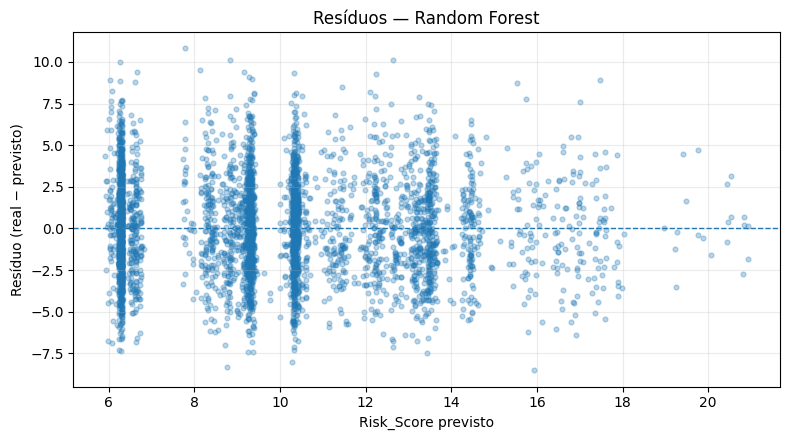

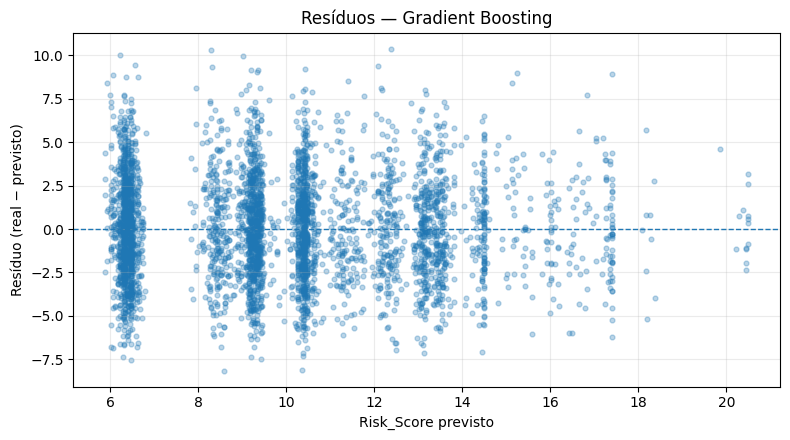

RESUMO DA ANÁLISE DOS RESÍDUOS


,Modelo,Resíduo médio,Desvio padrão dos resíduos,Mediana do resíduo,Percentil 95 do erro absoluto
0,Random Forest,0.0225,2.9531,-0.1132,5.7129
1,Gradient Boosting,0.0243,2.9528,-0.1022,5.7436


In [ ]:
# Análise dos resíduos — Random Forest e Gradient Boosting

registros_residuos = []

for nome, pipeline in modelos_regressao.items():

    valores_reais = np.asarray(y_test_r, dtype=float)
    valores_previstos = pipeline.predict(X_test)

    residuos = valores_reais - valores_previstos

    assert len(residuos) == len(X_test) == 4000
    assert np.isfinite(residuos).all()

    registros_residuos.append({
        "Modelo": nome,
        "Resíduo médio": np.mean(residuos),
        "Desvio padrão dos resíduos": np.std(
            residuos, ddof=1
        ),
        "Mediana do resíduo": np.median(residuos),
        "Percentil 95 do erro absoluto": np.percentile(
            np.abs(residuos), 95
        )
    })

    fig, ax = plt.subplots(figsize=(8, 4.5))

    ax.scatter(
        valores_previstos,
        residuos,
        alpha=0.3,
        s=12
    )

    ax.axhline(
        y=0,
        linestyle="--",
        linewidth=1
    )

    ax.set_title(f"Resíduos — {nome}")
    ax.set_xlabel("Risk_Score previsto")
    ax.set_ylabel("Resíduo (real − previsto)")
    ax.grid(alpha=0.25)

    fig.tight_layout()

    nome_arquivo = (
        "random_forest"
        if nome == "Random Forest"
        else "gradient_boosting"
    )

    fig.savefig(
        pasta_figuras /
        f"residuos_{nome_arquivo}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

tabela_residuos = pd.DataFrame(registros_residuos)

tabela_residuos.to_csv(
    pasta_tabelas / "ensembles_residuos.csv",
    index=False
)

print("RESUMO DA ANÁLISE DOS RESÍDUOS")
display(tabela_residuos.round(4))

### 12.1 Interpretação dos resíduos

Os modelos Random Forest e Gradient Boosting apresentaram resíduos médios próximos de zero, de 0,0225 e 0,0243, respectivamente, indicando ausência de viés médio expressivo nas previsões do conjunto de teste.

Os desvios padrão dos resíduos foram praticamente iguais, próximos de 2,95, confirmando a semelhança observada nas métricas de regressão. O percentil 95 do erro absoluto foi de 5,7129 para a Random Forest e 5,7436 para o Gradient Boosting.

Esses resultados indicam desempenho semelhante entre os modelos. Entretanto, resíduos médios próximos de zero não garantem ausência de padrões sistemáticos, cuja identificação depende também da inspeção dos gráficos de resíduos.

## 13. Tempo de treinamento isolado

Para complementar os tempos registrados durante a busca de hiperparâmetros, mede-se o tempo necessário para ajustar cada modelo com sua configuração já selecionada.

São realizadas cinco repetições independentes por modelo, utilizando cópias não treinadas dos Pipelines e o conjunto completo de treinamento.

A medição inclui o pré-processamento e o ajuste do algoritmo, mas não inclui GridSearchCV. São calculados o tempo médio, o desvio padrão e as estimativas de energia e CO₂.

Esse procedimento reproduz o protocolo de treinamento isolado adotado no Notebook 04 e não modifica os modelos utilizados na avaliação final.

In [ ]:
import time
from sklearn.base import clone

experimentos_ajuste = [
    ("Random Forest", "Classificação", rf_c, y_train_c),
    ("Random Forest", "Regressão", rf_r, y_train_r),
    ("Gradient Boosting", "Classificação", gb_c, y_train_c),
    ("Gradient Boosting", "Regressão", gb_r, y_train_r)
]

resultados_ajuste = []

for nome, tarefa, pipeline, y in experimentos_ajuste:

    tempos = []

    for repeticao in range(5):

        # Cópia não treinada, com os mesmos hiperparâmetros
        modelo_temporario = clone(pipeline)

        inicio = time.perf_counter()

        modelo_temporario.fit(X_train, y)

        tempo = time.perf_counter() - inicio
        tempos.append(tempo)

    tempo_medio = float(np.mean(tempos))
    desvio = float(np.std(tempos, ddof=1))

    energia = profiling.estimar_energia_carbono(
        tempo_medio
    )

    resultados_ajuste.append({
        "Modelo": nome,
        "Tarefa": tarefa,
        "Repetições": len(tempos),
        "Tempo médio ajuste (s)": tempo_medio,
        "Desvio padrão (s)": desvio,
        "Energia estimada (kWh)": energia["energia_kwh"],
        "CO2 estimado (g)": energia["emissao_co2_g"]
    })

tabela_ajuste_ensembles = pd.DataFrame(
    resultados_ajuste
)

tabela_ajuste_ensembles.to_csv(
    pasta_tabelas / "ensembles_treinamento_isolado.csv",
    index=False,
    float_format="%.16g"
)

print("TREINAMENTO ISOLADO — CINCO REPETIÇÕES")

display(
    tabela_ajuste_ensembles.style.format({
        "Tempo médio ajuste (s)": "{:.6f}",
        "Desvio padrão (s)": "{:.6f}",
        "Energia estimada (kWh)": "{:.6e}",
        "CO2 estimado (g)": "{:.6e}"
    })
)

print("\nMedições concluídas sem modificar os modelos originais.")

TREINAMENTO ISOLADO — CINCO REPETIÇÕES


,Modelo,Tarefa,Repetições,Tempo médio ajuste (s),Desvio padrão (s),Energia estimada (kWh),CO2 estimado (g)
0,Random Forest,Classificação,5,0.475853,0.009733,5.948160e-06,2.724257e-04
1,Random Forest,Regressão,5,0.852278,0.010980,1.065347e-05,4.879290e-04
2,Gradient Boosting,Classificação,5,0.502325,0.050578,6.279064e-06,2.875811e-04
3,Gradient Boosting,Regressão,5,0.550386,0.074789,6.879827e-06,3.150961e-04



Medições concluídas sem modificar os modelos originais.


### 13.1 Interpretação do tempo de treinamento

No treinamento isolado, o Gradient Boosting apresentou menor tempo médio na regressão. Na classificação, os tempos foram próximos: nesta execução a Random Forest foi ligeiramente mais rápida, mas a diferença ficou dentro da variabilidade observada e se inverteu entre execuções do Colab, o que recomenda cautela, considerando as cinco repetições realizadas.

Na inferência, o Gradient Boosting apresentou menor tempo médio nas duas tarefas, conforme os resultados registrados na Seção 11.

As medições de treinamento isolado incluem o pré-processamento e o ajuste dos modelos com hiperparâmetros previamente selecionados, mas não incluem a busca por validação cruzada. As estimativas de energia e CO₂ utilizam uma potência assumida de 45 W e não representam medições físicas de consumo.



In [ ]:
# Conferência dos tempos registrados nos CSVs
# Não executa treinamentos nem inferências

dados_inferencia = pd.read_csv(
    pasta_tabelas / "ensembles_inferencia.csv"
)

dados_ajuste = pd.read_csv(
    pasta_tabelas / "ensembles_treinamento_isolado.csv"
)

for tarefa in ["Classificação", "Regressão"]:

    inf = dados_inferencia[
        dados_inferencia["Tarefa"] == tarefa
    ].set_index("Modelo")

    ajuste = dados_ajuste[
        dados_ajuste["Tarefa"] == tarefa
    ].set_index("Modelo")

    rf_inf = inf.loc["Random Forest", "Tempo médio (s)"]
    gb_inf = inf.loc["Gradient Boosting", "Tempo médio (s)"]

    rf_ajuste = ajuste.loc[
        "Random Forest", "Tempo médio ajuste (s)"
    ]
    gb_ajuste = ajuste.loc[
        "Gradient Boosting", "Tempo médio ajuste (s)"
    ]

    rf_desvio = ajuste.loc[
        "Random Forest", "Desvio padrão (s)"
    ]
    gb_desvio = ajuste.loc[
        "Gradient Boosting", "Desvio padrão (s)"
    ]

    print(f"\n{tarefa.upper()}")

    print(
    f"Inferência: RF={rf_inf:.6f}s | "
    f"GB={gb_inf:.6f}s | "
    f"razão RF/GB = {rf_inf / gb_inf:.2f}"
    )

    print(
    f"Treinamento isolado: RF={rf_ajuste:.6f}s | "
    f"GB={gb_ajuste:.6f}s | "
    f"razão RF/GB = {rf_ajuste / gb_ajuste:.2f}"
    )

    print(
        f"Desvio do treinamento: "
        f"RF={rf_desvio:.6f}s | "
        f"GB={gb_desvio:.6f}s"
    )


CLASSIFICAÇÃO
Inferência: RF=0.025591s | GB=0.004401s | razão RF/GB = 5.81
Treinamento isolado: RF=0.475853s | GB=0.502325s | razão RF/GB = 0.95
Desvio do treinamento: RF=0.009733s | GB=0.050578s

REGRESSÃO
Inferência: RF=0.046505s | GB=0.005517s | razão RF/GB = 8.43
Treinamento isolado: RF=0.852278s | GB=0.550386s | razão RF/GB = 1.55
Desvio do treinamento: RF=0.010980s | GB=0.074789s


## 14. Síntese da generalização e do compromisso entre viés e variância

Os quatro ensembles apresentaram diferenças relativamente pequenas entre treinamento, validação cruzada e teste, sem evidência de *overfitting* acentuado nas configurações escolhidas. Na classificação, os gaps de F1 treino–teste foram **0,0252** (Random Forest) e **0,0157** (Gradient Boosting); na regressão, os gaps de RMSE foram **0,0201** e **0,0024**, respectivamente.

Na perspectiva de viés e variância, a agregação de árvores da Random Forest busca principalmente reduzir a **variância**. Contudo, a configuração selecionada (`max_features=1.0`) não utiliza subamostragem de variáveis por divisão e aproxima seu comportamento do Bagging. O Gradient Boosting combina árvores sequencialmente para corrigir erros anteriores, enquanto profundidade limitada, taxa de aprendizado e amostragem controlam a complexidade e o risco de sobreajuste.

O desempenho preditivo foi **moderado**: os recalls dos ensembles ficaram próximos de 55%, enquanto o R² de regressão ficou próximo de 0,48. Os pequenos gaps são compatíveis com generalização estável, mas **não permitem medir ou descartar um possível viés elevado (*underfitting*)**. Da mesma forma, o patamar das curvas de erro não é, isoladamente, a medida numérica desse viés.

**Limites da busca:** alguns hiperparâmetros foram selecionados nos extremos da grade original, como `max_depth=6` nas Random Forests, `n_estimators=50` no Gradient Boosting de classificação e `max_depth=2` no Gradient Boosting de regressão.

Isso significa que os melhores resultados são os melhores **entre as configurações avaliadas**, não necessariamente os melhores valores possíveis. A seleção foi realizada exclusivamente com os dados de treinamento e validação cruzada. Os modelos permaneceram inalterados após a avaliação no conjunto de teste, preservando o protocolo experimental.

Portanto, os quatro ensembles podem ser descritos como **bem ajustados quanto à generalização observada, com capacidade preditiva moderada e limitações do espaço de variáveis e de hiperparâmetros**. Os resultados devem ser interpretados considerando as seis variáveis disponíveis, uma única divisão treino/teste e a variabilidade entre folds.